# OPS0077 NTC: cell cycle phase score, exploration and QC

Explore the circular cell cycle score produced by `scripts/ops0077_cell_cycle_score.py`.

**Score columns** (`reports/ops0077_cell_cycle_score/cell_cycle_scores.csv.gz`)

| column | meaning |
|---|---|
| `cc_phase` | final score in [0, 1), circular (0 and 1 are the same point). Filled from `dna+pcs`, else `dna`, else empty |
| `cc_phase_dna` | closed principal curve through phosphorylated-Rb fraction, p21, pRb and relative DNA content |
| `cc_phase_dna_pcs` | same plus the PCs that track the phase without being batch or size driven |
| `cc_phase_markers` | markers only (no DNA), aligned to the DNA phase. **QC only**: it agrees poorly with the DNA-anchored phase |
| `cc_curve_dist_*` | distance of the cell from the fitted cycle curve (large = off-cycle or noisy) |
| `z_phos`, `z_p21`, `z_pRb`, `z_dna` | the per-well robust-z axes used in the fit |

Phase 0 is anchored at the lowest-DNA part of the loop (G1). The loop runs forward through the p21 minimum (S) to the DNA maximum (G2/M) and back to G1.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path("..") if Path("../reports").exists() else Path(".")
REP = ROOT / "reports/ops0077_cell_cycle_score"
res = pd.read_csv(REP / "cell_cycle_scores.csv.gz", index_col=0)
summ = json.load(open(REP / "summary.json"))
pcs_screen = pd.read_csv(REP / "pc_screening.csv")
print(summ)
res.head()

{'cells_total': 52220, 'cells_markers': 42410, 'cells_dna': 35633, 'cells_dna_pcs': 35633, 'kept_pcs': ['prb_p21_coloc_PC1', 'prb_p21_coloc_PC2'], 'source_counts': {'dna+pcs': 35633, '': 16587}, 'markers_vs_dna_circular_agreement': 0.3360786430228753, 'well_eta2_phase': 0.0008830450681154128}


,z_phos,z_p21,z_pRb,z_dna,cell_key,well,nuc_area_px,dapi_log_area,dna_rel_R234,dna_reliable,...,x_cp,y_cp,cc_phase_dna,cc_curve_dist_dna,cc_phase_markers,cc_curve_dist_markers,cc_phase_dna_pcs,cc_phase,cc_phase_source,cc_phase_angle_rad
obs_name,,,,,,,,,,,,,,,,,,,,,
A/1/0|21521877|0,0.953048,-0.201355,0.955174,4.000000,A/1/0|21521877,A/1/0,2176.000454,7.827873,0.858680,True,...,45572.554913,53722.497110,0.570193,1.241012,0.184030,0.337239,0.588883,0.588883,dna+pcs,3.700063
A/1/0|27047760|1,0.014480,0.906245,0.413617,-0.750170,A/1/0|27047760,A/1/0,1158.999532,7.571039,-0.100527,True,...,13415.401575,66835.086614,0.009820,0.247328,0.359095,0.386772,0.009831,0.009831,dna+pcs,0.061773
A/1/0|20873972|2,-1.076661,1.630372,0.350743,-1.875390,A/1/0|20873972,A/1/0,2294.000150,7.239313,-0.325895,True,...,104653.255814,48185.255814,0.988837,2.149575,0.510747,0.714812,0.000000,0.000000,dna+pcs,0.000000
A/1/0|39951811|3,1.162080,1.120971,2.073703,-3.976139,A/1/0|39951811,A/1/0,413.999982,6.864533,-0.746649,True,...,82362.285714,95330.476190,0.000000,5.449429,0.254573,1.427563,0.043848,0.043848,dna+pcs,0.275502
A/1/0|16993631|4,0.902625,0.036033,1.247731,4.000000,A/1/0|16993631,A/1/0,3029.999927,7.948430,1.073597,True,...,41626.194286,43124.457143,0.587604,1.366221,0.211395,0.414448,0.588883,0.588883,dna+pcs,3.700063


## 1. Coverage: which cells have a score?

In [2]:
cov = pd.DataFrame({
    "cells": [len(res), res["z_phos"].notna().sum() if "z_phos" in res else np.nan,
              res["cc_phase_dna"].notna().sum(), res["cc_phase_dna_pcs"].notna().sum(), res["cc_phase"].notna().sum()],
}, index=["all cells", "complete markers", "cc_phase_dna", "cc_phase_dna_pcs", "cc_phase (final)"])
cov["fraction"] = cov["cells"] / len(res)
display(cov)

# why do cells lack a DNA-based score?
miss = res[res["cc_phase_dna"].isna()]
display(pd.DataFrame({
    "n": [len(miss), (~miss["dna_reliable"].fillna(False).astype(bool)).sum(), (miss["nucleus_found_R234"] == False).sum(),
          miss["z_phos"].isna().sum()],
}, index=["no cc_phase_dna", "dna not flagged reliable / not in DAPI table", "no nucleus in R2-R4", "missing marker axes"]))

,cells,fraction
all cells,52220,1.000000
complete markers,42410,0.812141
cc_phase_dna,35633,0.682363
cc_phase_dna_pcs,35633,0.682363
cc_phase (final),35633,0.682363


/var/folders/rg/j09rhqk941ng_40p8642z0cr0000gn/T/ipykernel_4743/2452515484.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  "n": [len(miss), (~miss["dna_reliable"].fillna(False).astype(bool)).sum(), (miss["nucleus_found_R234"] == False).sum(),


,n
no cc_phase_dna,16587
dna not flagged reliable / not in DAPI table,16201
no nucleus in R2-R4,2501
missing marker axes,9810


## 2. Score distribution and the loop in marker space

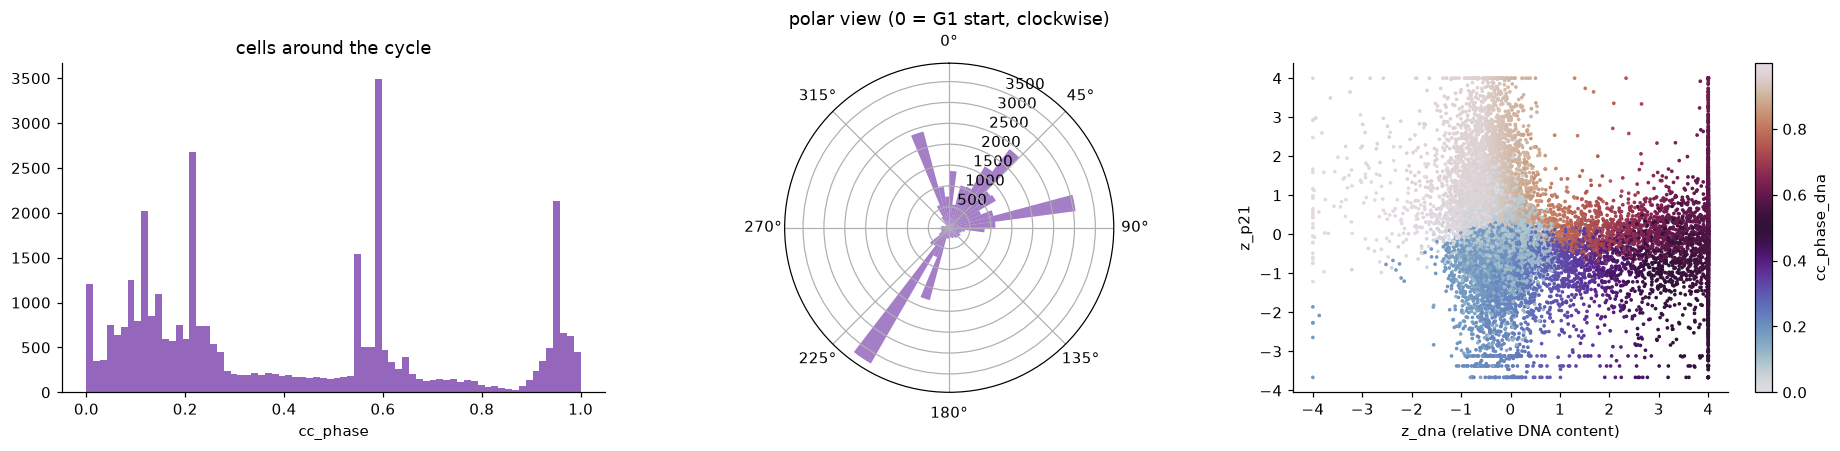

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].hist(res["cc_phase"].dropna(), bins=72, color="C4")
ax[0].set_xlabel("cc_phase"); ax[0].set_title("cells around the cycle")

# polar histogram
axp = fig.add_subplot(1, 3, 2, projection="polar"); ax[1].remove()
th = 2 * np.pi * res["cc_phase"].dropna().values
cnt, edges = np.histogram(th, bins=48, range=(0, 2 * np.pi))
axp.bar(edges[:-1], cnt, width=np.diff(edges), align="edge", color="C4", alpha=.85)
axp.set_theta_zero_location("N"); axp.set_theta_direction(-1); axp.set_title("polar view (0 = G1 start, clockwise)")

d = res.dropna(subset=["cc_phase_dna"]).sample(min(15000, res["cc_phase_dna"].notna().sum()), random_state=0)
h = ax[2].scatter(d["z_dna"], d["z_p21"], c=d["cc_phase_dna"], s=2, cmap="twilight", rasterized=True)
ax[2].set_xlabel("z_dna (relative DNA content)"); ax[2].set_ylabel("z_p21"); plt.colorbar(h, ax=ax[2], label="cc_phase_dna")
plt.tight_layout()

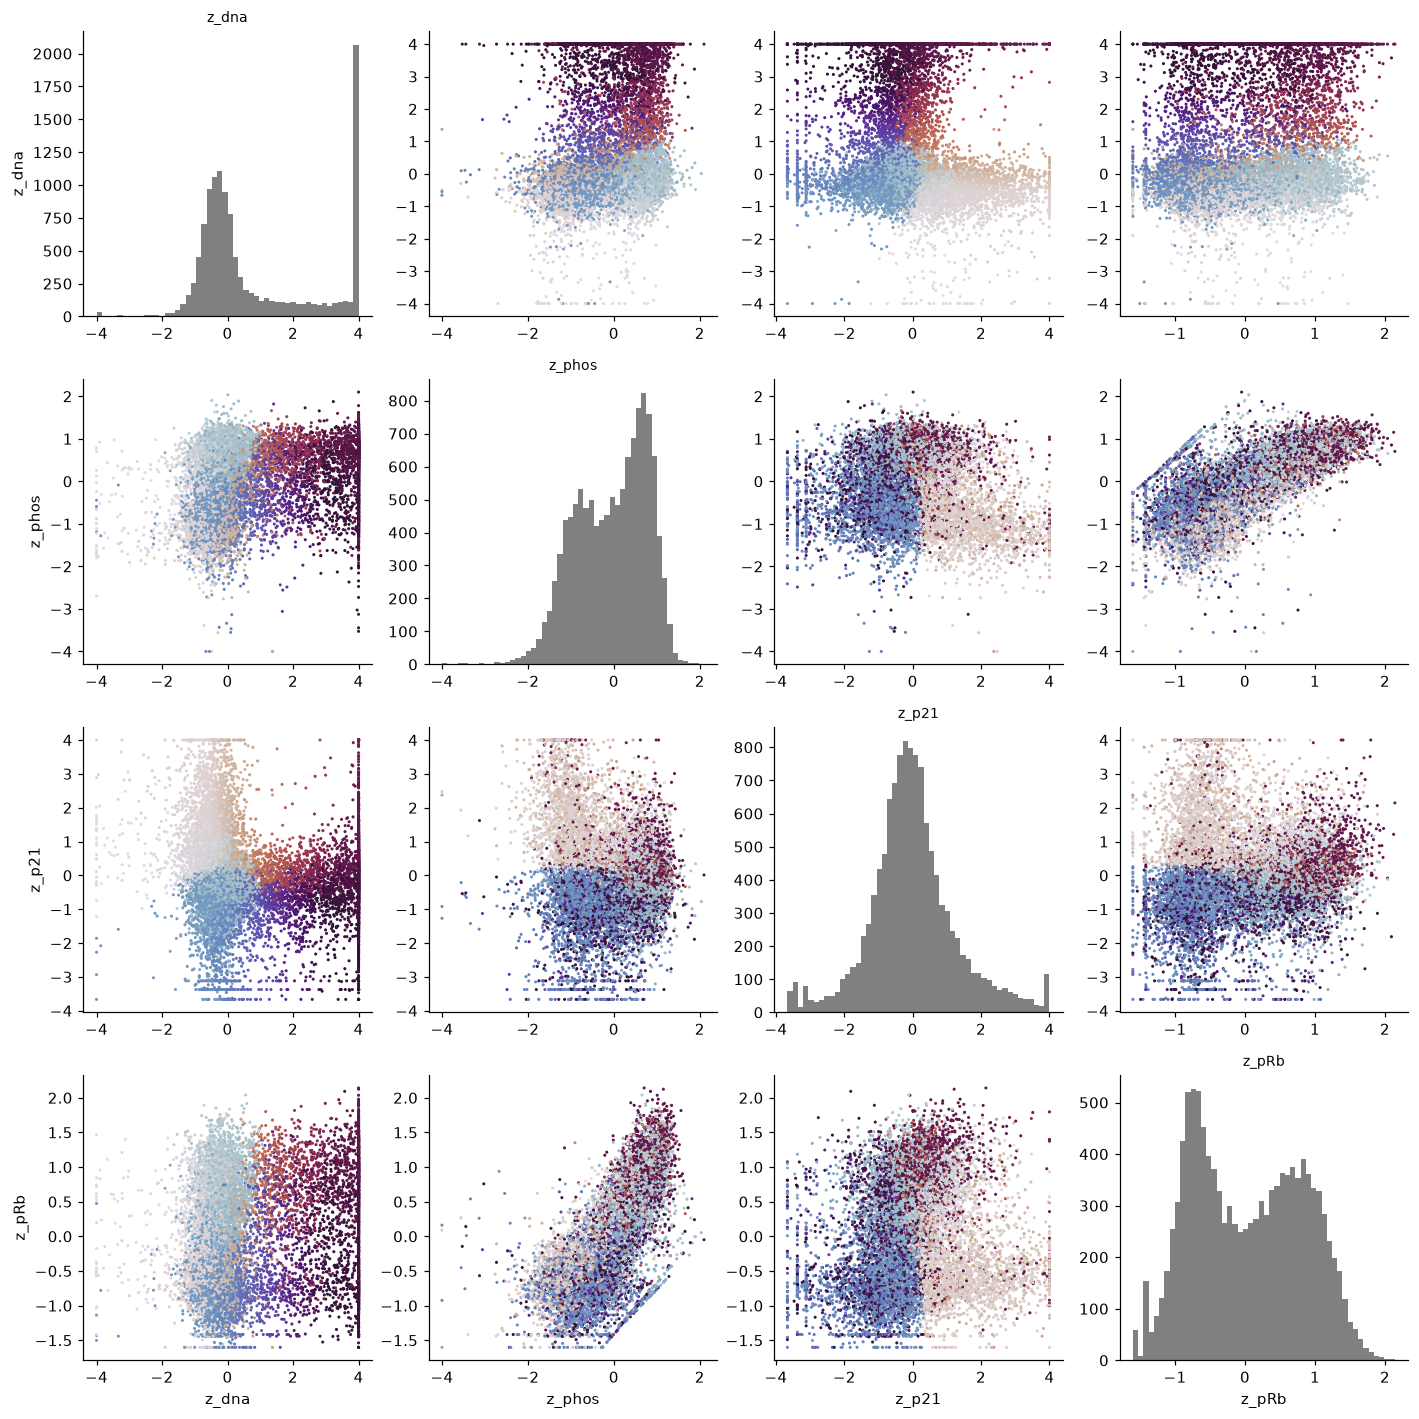

In [4]:
# every pairwise view of the four fitted axes, coloured by phase (cyclic colormap)
axes = ["z_dna", "z_phos", "z_p21", "z_pRb"]
d = res.dropna(subset=["cc_phase_dna"]).sample(min(12000, res["cc_phase_dna"].notna().sum()), random_state=1)
fig, ax = plt.subplots(len(axes), len(axes), figsize=(13, 13))
for i, y in enumerate(axes):
    for j, x in enumerate(axes):
        a = ax[i, j]
        if i == j:
            a.hist(d[x], bins=50, color="gray"); a.set_title(x, fontsize=9)
        else:
            a.scatter(d[x], d[y], c=d["cc_phase_dna"], s=1, cmap="twilight", rasterized=True)
        if j == 0: a.set_ylabel(y)
        if i == len(axes) - 1: a.set_xlabel(x)
plt.tight_layout()

## 3. Marker profiles around the cycle

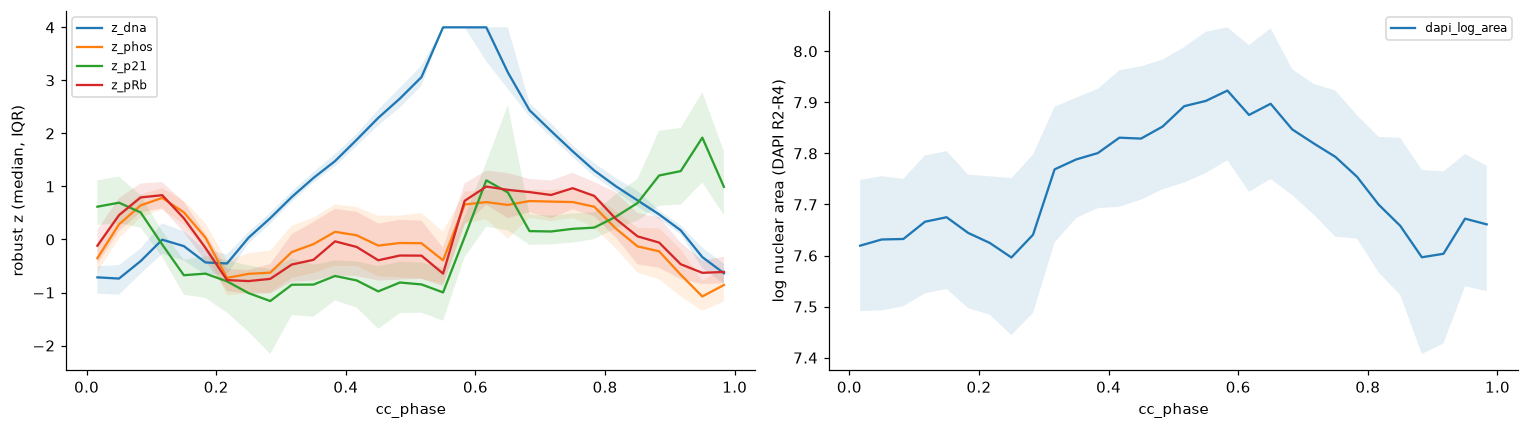

In [5]:
def profile(df, phase_col, cols, nb=30, ax=None, ylabel=""):
    b = pd.cut(df[phase_col], np.linspace(0, 1, nb + 1))
    mid = np.linspace(0, 1, nb + 1)[:-1] + 0.5 / nb
    for c in cols:
        g = df.groupby(b, observed=True)[c]
        ax.plot(mid, g.median().values, label=c)
        ax.fill_between(mid, g.quantile(.25).values, g.quantile(.75).values, alpha=.12)
    ax.set_xlabel(phase_col); ax.set_ylabel(ylabel); ax.legend(fontsize=8)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
profile(res, "cc_phase", ["z_dna", "z_phos", "z_p21", "z_pRb"], ax=ax[0], ylabel="robust z (median, IQR)")
profile(res, "cc_phase", ["dapi_log_area"], ax=ax[1], ylabel="log nuclear area (DAPI R2-R4)")
plt.tight_layout()

# expected biology: p21 lowest around S, pRb and phosphorylated fraction rising in late G1 and staying high, DNA peaking in G2/M

In [6]:
# raw (un-normalised) DNA content and nuclear area, per phase decile
res["phase_bin"] = pd.cut(res["cc_phase"], np.linspace(0, 1, 11), include_lowest=True)
display(res.groupby("phase_bin", observed=True)[["dna_rel_R234", "dapi_log_area", "nuc_area_px"]].agg(["median", "count"]).round(2))

dna_rel_R234       dapi_log_area       nuc_area_px      
                    median count        median count      median count
phase_bin                                                             
(-0.001, 0.1]        -0.15  5451          7.62  5451      2080.0  5451
(0.1, 0.2]           -0.05  6748          7.66  6748      2152.0  6748
(0.2, 0.3]           -0.06  5863          7.62  5863      1848.0  5863
(0.3, 0.4]            0.20  1441          7.79  1441      2363.0  1441
(0.4, 0.5]            0.42  1202          7.84  1202      2538.5  1202
(0.5, 0.6]            0.91  6679          7.91  6679      2742.0  6679
(0.6, 0.7]            0.67  1891          7.88  1891      2704.0  1891
(0.7, 0.8]            0.31   936          7.79   936      2448.0   936
(0.8, 0.9]            0.13   449          7.66   449      2160.0   449
(0.9, 1.0]           -0.09  4973          7.66  4973      2263.0  4973

## 4. Confounder QC: well, DNA reliability flags, local density, area
The phase distribution should be the same across wells and across QC strata. Differences point to technical effects.

well


,mean_phase,resultant_len,n
well,,,
A/1/0,0.155,0.254,13899.0
A/2/0,0.139,0.263,11254.0
A/3/0,0.137,0.266,10480.0


dense_field


,mean_phase,resultant_len,n
dense_field,,,
False,0.162,0.244,18672.0
True,0.128,0.280,16961.0


dna_R1_any_saturated


,mean_phase,resultant_len,n
dna_R1_any_saturated,,,
False,0.113,0.546,21533.0
True,0.517,0.231,14100.0


dna_reliable


/var/folders/rg/j09rhqk941ng_40p8642z0cr0000gn/T/ipykernel_4743/2621322656.py:2: RuntimeWarning: Mean of empty slice
  z = np.exp(2j * np.pi * p.dropna().values).mean()
<project-root>/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,mean_phase,resultant_len,n
dna_reliable,,,
False,NaN,NaN,0.0
True,0.145,0.26,35633.0


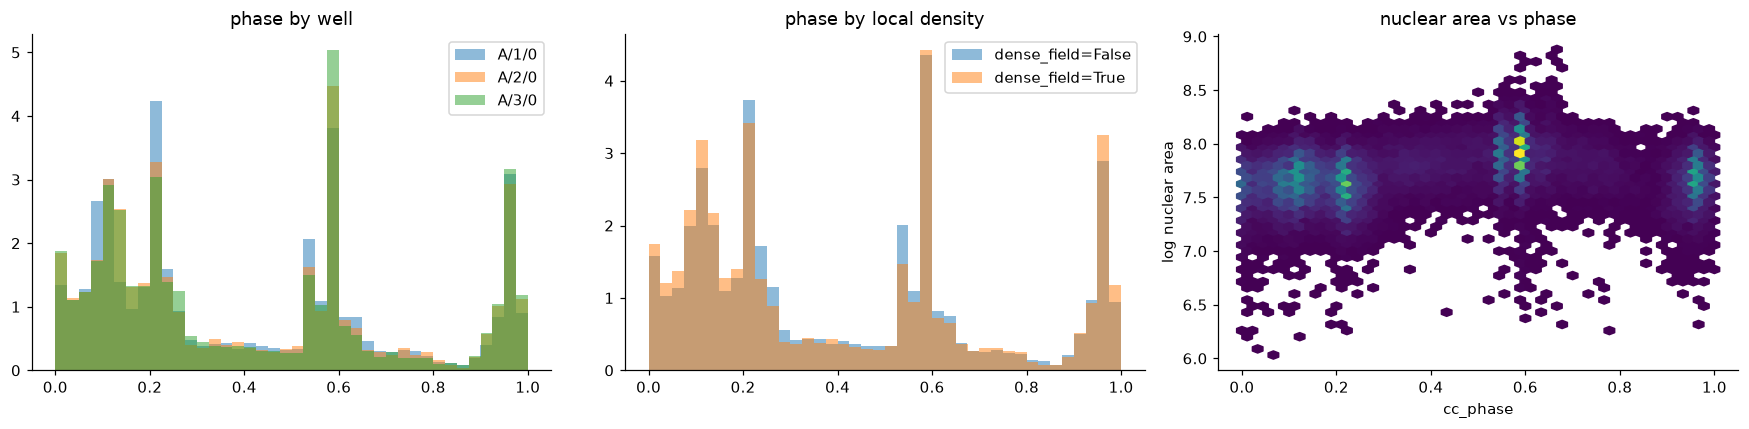

In [7]:
def circ_mean(p):
    z = np.exp(2j * np.pi * p.dropna().values).mean()
    return pd.Series({"mean_phase": (np.angle(z) / (2 * np.pi)) % 1, "resultant_len": abs(z), "n": p.notna().sum()})

for col in ["well", "dense_field", "dna_R1_any_saturated", "dna_reliable"]:
    print(col); display(res.groupby(col)["cc_phase"].apply(circ_mean).unstack().round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for w, g in res.groupby("well"):
    ax[0].hist(g["cc_phase"].dropna(), bins=40, density=True, alpha=.5, label=w)
ax[0].legend(); ax[0].set_title("phase by well")
for k, g in res.groupby("dense_field"):
    ax[1].hist(g["cc_phase"].dropna(), bins=40, density=True, alpha=.5, label=f"dense_field={k}")
ax[1].legend(); ax[1].set_title("phase by local density")
d = res.dropna(subset=["cc_phase", "dapi_log_area"])
ax[2].hexbin(d["cc_phase"], d["dapi_log_area"], gridsize=45, cmap="viridis", mincnt=1)
ax[2].set_xlabel("cc_phase"); ax[2].set_ylabel("log nuclear area"); ax[2].set_title("nuclear area vs phase")
plt.tight_layout()

95th percentile distance = 2.48; cells above it could be flagged as off-cycle / low quality


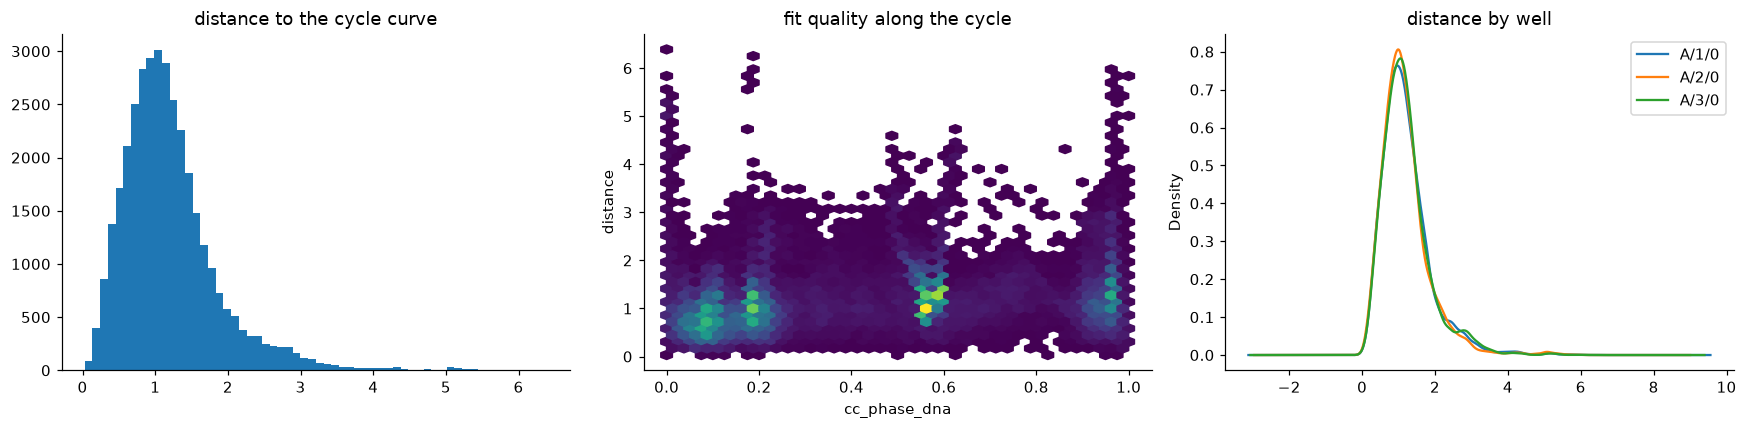

In [8]:
# distance from the fitted cycle: are poorly-fit cells concentrated somewhere?
d = res.dropna(subset=["cc_curve_dist_dna"])
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(d["cc_curve_dist_dna"], bins=60); ax[0].set_title("distance to the cycle curve")
ax[1].hexbin(d["cc_phase_dna"], d["cc_curve_dist_dna"], gridsize=40, cmap="viridis", mincnt=1)
ax[1].set_xlabel("cc_phase_dna"); ax[1].set_ylabel("distance"); ax[1].set_title("fit quality along the cycle")
d.groupby("well")["cc_curve_dist_dna"].plot(kind="kde", ax=ax[2], legend=True); ax[2].set_title("distance by well")
plt.tight_layout()
thr = d["cc_curve_dist_dna"].quantile(0.95)
print(f"95th percentile distance = {thr:.2f}; cells above it could be flagged as off-cycle / low quality")

## 5. Spatial layout of the score (batch / edge / density effects)

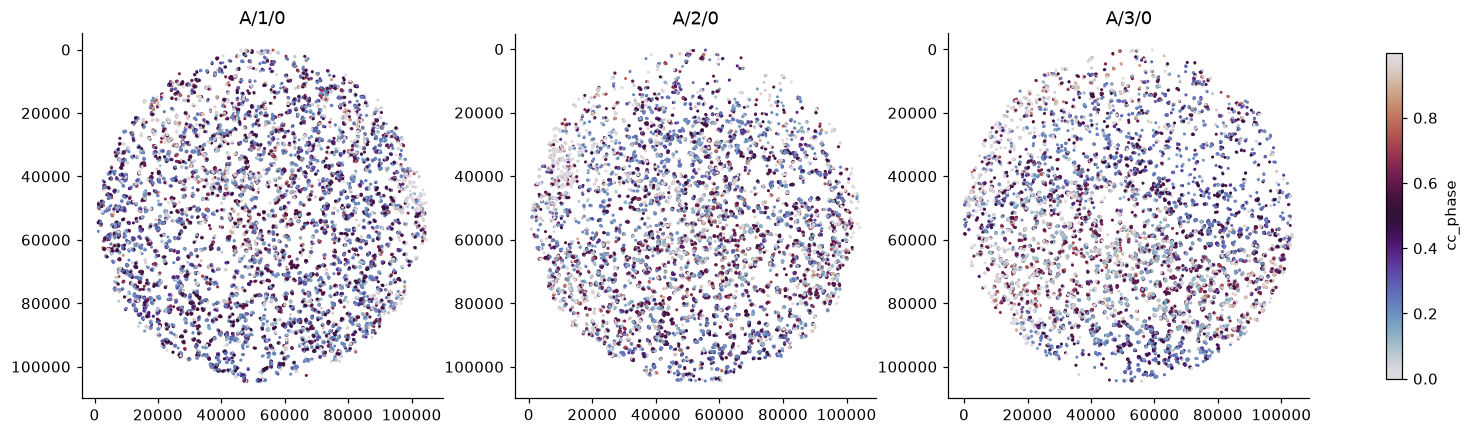

In [9]:
wells = sorted(res["well"].dropna().unique())
fig, ax = plt.subplots(1, len(wells), figsize=(6 * len(wells), 5.5))
for a, w in zip(np.atleast_1d(ax), wells):
    g = res[(res["well"] == w) & res["cc_phase"].notna()]
    h = a.scatter(g["x_cp"], g["y_cp"], c=g["cc_phase"], s=1, cmap="twilight", rasterized=True)
    a.set_title(w); a.set_aspect("equal"); a.invert_yaxis()
plt.colorbar(h, ax=ax, label="cc_phase", shrink=.7)

## 6. Is the DNA axis driving everything? Robustness of the score
Compare the score across fits: DNA-anchored, DNA plus PCs, and markers only. The circular difference between two phases is `((a - b + 0.5) % 1) - 0.5`.

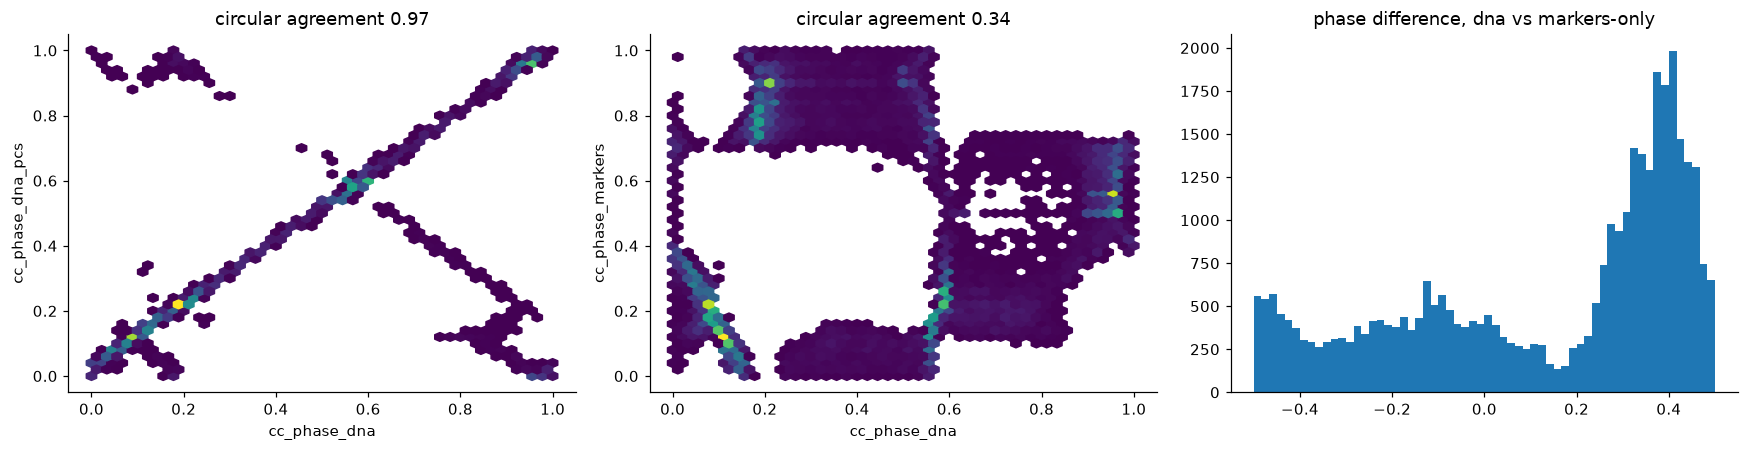

In [10]:
def cdiff(a, b): return (a - b + 0.5) % 1.0 - 0.5

pairs = [("cc_phase_dna", "cc_phase_dna_pcs"), ("cc_phase_dna", "cc_phase_markers")]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, (x, y) in zip(ax[:2], pairs):
    d = res.dropna(subset=[x, y])
    a.hexbin(d[x], d[y], gridsize=45, cmap="viridis", mincnt=1); a.set_xlabel(x); a.set_ylabel(y)
    r = abs(np.exp(2j * np.pi * cdiff(d[x], d[y])).mean())
    a.set_title(f"circular agreement {r:.2f}")
d = res.dropna(subset=["cc_phase_dna", "cc_phase_markers"])
ax[2].hist(cdiff(d["cc_phase_dna"], d["cc_phase_markers"]), bins=60)
ax[2].set_title("phase difference, dna vs markers-only"); plt.tight_layout()

In [11]:
# which phases does a markers-only fit confuse? (mean abs difference per DNA-anchored phase bin)
d = res.dropna(subset=["cc_phase_dna", "cc_phase_markers"]).copy()
d["bin"] = pd.cut(d["cc_phase_dna"], np.linspace(0, 1, 11), include_lowest=True)
d["absdiff"] = cdiff(d["cc_phase_dna"], d["cc_phase_markers"]).abs()
d.groupby("bin", observed=True)["absdiff"].agg(["mean", "median", "count"]).round(3)

,mean,median,count
bin,,,
"(-0.001, 0.1]",0.190,0.172,6359
"(0.1, 0.2]",0.211,0.174,7170
"(0.2, 0.3]",0.364,0.361,3778
"(0.3, 0.4]",0.364,0.382,1295
"(0.4, 0.5]",0.389,0.399,1281
"(0.5, 0.6]",0.343,0.370,7161
"(0.6, 0.7]",0.369,0.420,1162
"(0.7, 0.8]",0.408,0.439,1040
"(0.8, 0.9]",0.349,0.387,821


## 7. PC screening
PCs were kept if they have a circular association with the phase (R² of a 2-harmonic fit ≥ 0.03), little well dependence (η² < 0.1) and no strong area dependence (|ρ| < 0.6).

In [12]:
display(pcs_screen.sort_values("harmonic_r2_phase", ascending=False).round(3))
print("kept:", summ["kept_pcs"])

,pc,n,coverage,harmonic_r2_phase,rho_dna,rho_area,eta2_well,keep
9,prb_rb_coloc_PC2,35633,1.000,0.121,0.336,-0.038,0.261,False
8,prb_rb_coloc_PC1,35633,1.000,0.110,0.263,0.293,0.148,False
22,rb_p21_integrated_PC1,13999,0.393,0.102,0.147,0.036,0.002,False
4,p21_PC1,14448,0.405,0.101,0.140,0.042,0.000,False
18,rb_p21_channels_PC1,13999,0.393,0.101,-0.140,-0.039,-0.000,False
16,prb_p21_integrated_PC1,11094,0.311,0.087,-0.142,-0.063,0.002,False
14,prb_p21_coloc_PC1,35633,1.000,0.082,0.184,0.025,0.094,True
12,prb_p21_channels_PC1,11094,0.311,0.079,0.126,0.062,0.000,False
15,prb_p21_coloc_PC2,35633,1.000,0.056,0.118,0.057,0.091,True
21,rb_p21_coloc_PC2,35633,1.000,0.050,-0.202,-0.009,0.182,False


kept: ['prb_p21_coloc_PC1', 'prb_p21_coloc_PC2']


## 8. Link to the full feature matrix
Which of the 4i features (all 2,250) vary with the phase? Load the h5ad and compute a circular-linear association (R² of a 2-harmonic fit). This can take a minute.

In [13]:
import anndata as ad
adata = ad.read_h5ad(ROOT / "data/altair/ops0077_4i/OPS0077_NTC_OrganelleProfiler_pRb_Rb_p21.h5ad")
sc = res["cc_phase"].reindex(adata.obs_names)
m = sc.notna().values
t = 2 * np.pi * sc.values[m]
D = np.column_stack([np.ones(m.sum()), np.sin(t), np.cos(t), np.sin(2 * t), np.cos(2 * t)])
X = np.asarray(adata.X[m], dtype=float)
r2 = np.full(X.shape[1], np.nan)
for j in range(X.shape[1]):
    x = X[:, j]; ok = np.isfinite(x)
    if ok.sum() < 5000 or np.nanstd(x) == 0: continue
    beta, *_ = np.linalg.lstsq(D[ok], x[ok], rcond=None)
    r2[j] = 1 - np.var(x[ok] - D[ok] @ beta) / np.var(x[ok])
feat = pd.DataFrame({"feature": adata.var_names, "harmonic_r2": r2, "organelle": adata.var["organelle"].values,
                     "category": adata.var["category"].values}).dropna()
display(feat.sort_values("harmonic_r2", ascending=False).head(30))
feat.groupby("organelle")["harmonic_r2"].describe()[["count", "mean", "50%", "max"]]

,feature,harmonic_r2,organelle,category
724,cp_single_object_pRb_cell_Intensity_Integrated...,0.325937,,
862,cp_single_object_pRb_cytoplasm_Intensity_Integ...,0.271028,,
2136,cp_single_object_p21_cytoplasm_Intensity_MeanI...,0.268912,,
20,op_nuclei_moments_weighted_hu_0_min,0.258423,nuclei,morphology
136,op_nuclei_intensity_mean_mean,0.254105,nuclei,intensity
137,op_nuclei_intensity_mean_median,0.253134,nuclei,intensity
141,op_nuclei_intensity_mean_max,0.247610,nuclei,intensity
736,cp_single_object_pRb_cell_Intensity_StdIntensity,0.247538,,
1650,op_4i_r4_p21_normalized_radial_position_min,0.247393,4i_r4_p21,localization
111,op_nuclei_intensity_max_max,0.244777,nuclei,intensity


/var/folders/rg/j09rhqk941ng_40p8642z0cr0000gn/T/ipykernel_4743/3572627432.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  feat.groupby("organelle")["harmonic_r2"].describe()[["count", "mean", "50%", "max"]]


,count,mean,50%,max
organelle,,,,
,1407.0,0.037687,0.006124,0.325937
4i_r3_prb,221.0,0.034448,0.008611,0.195427
4i_r3_rb,221.0,0.014503,0.001760,0.204303
4i_r4_p21,221.0,0.040374,0.004054,0.247393
cell,16.0,0.019909,0.000651,0.096440
nuclei,136.0,0.045960,0.002802,0.258423


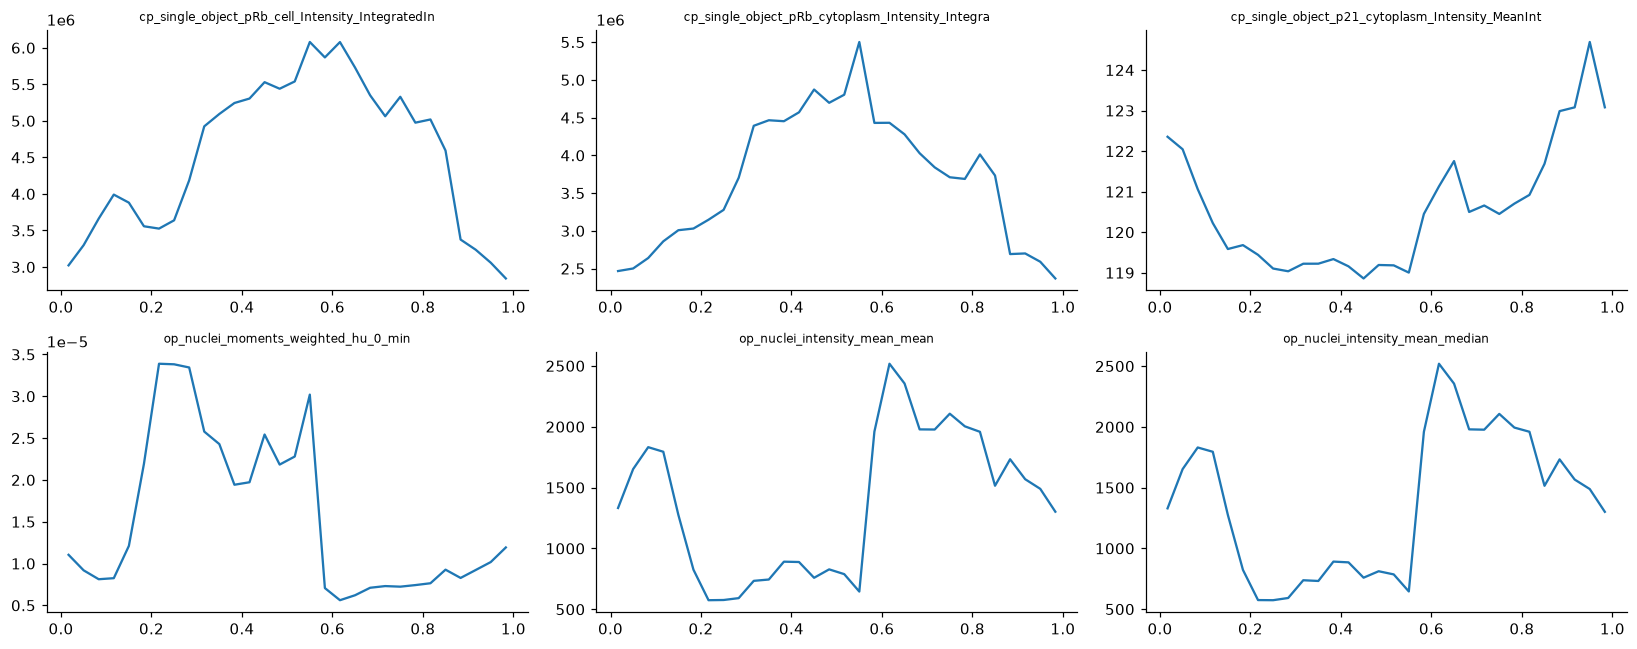

In [14]:
# trace a few top features around the cycle
top = feat.sort_values("harmonic_r2", ascending=False)["feature"].head(6).tolist()
Xd = pd.DataFrame(adata[:, top].X, index=adata.obs_names, columns=top).join(res["cc_phase"])
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for a, f in zip(ax.ravel(), top):
    g = Xd.groupby(pd.cut(Xd["cc_phase"], np.linspace(0, 1, 31)), observed=True)[f]
    a.plot(np.linspace(0, 1, 31)[:-1] + 1/60, g.median().values); a.set_title(f[:48], fontsize=8)
plt.tight_layout()

## 9. Embedding coloured by phase (UMAP on the fitted axes)

<project-root>/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
<project-root>/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


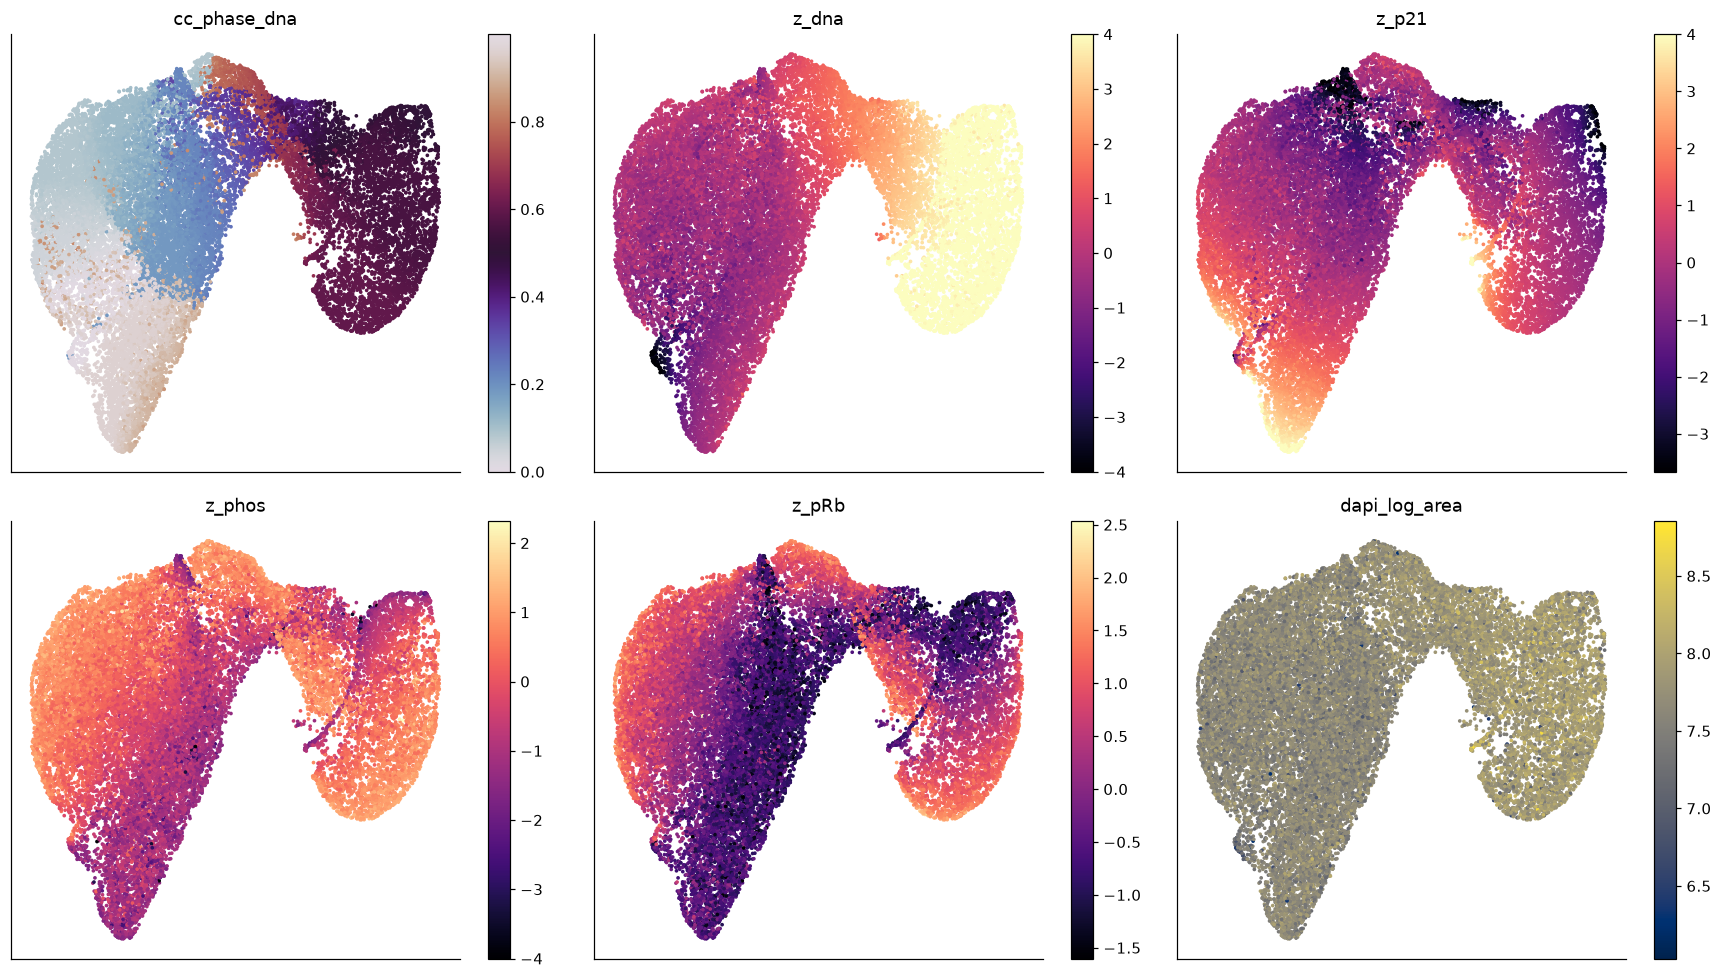

In [15]:
import umap
d = res.dropna(subset=["cc_phase_dna"]).sample(min(25000, res["cc_phase_dna"].notna().sum()), random_state=0)
emb = umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=0).fit_transform(d[["z_phos", "z_p21", "z_pRb", "z_dna"]].values * [1, 1, 1, 1.5])
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for a, (c, cm) in zip(ax.ravel(), [("cc_phase_dna", "twilight"), ("z_dna", "magma"), ("z_p21", "magma"),
                                    ("z_phos", "magma"), ("z_pRb", "magma"), ("dapi_log_area", "cividis")]):
    h = a.scatter(emb[:, 0], emb[:, 1], c=d[c], s=2, cmap=cm, rasterized=True); a.set_title(c); a.set_xticks([]); a.set_yticks([])
    plt.colorbar(h, ax=a)
plt.tight_layout()

## 10. Hand-off to the scRNA-seq integration
For matching to scRNA-seq the circular phase should be used as a pair `(sin, cos)`, never as a raw 0-1 number, because 0 and 1 are the same biological state.

In [ ]:
res["phase_sin"] = np.sin(2 * np.pi * res["cc_phase"])
res["phase_cos"] = np.cos(2 * np.pi * res["cc_phase"])
res[["cell_key", "well", "cc_phase", "phase_sin", "phase_cos", "cc_phase_source"]].dropna(subset=["cc_phase"]).head()